# 🦎 MECCHA CHAMELEON — YOLO 모델 준비 노트북

**목표:** 실습실 컴퓨터에서도 독립된 Python 환경을 확인·설치하고, **`meccha-yolo` 커널을 등록**한 다음, **YOLO26n 사전학습 모델**을 불러와 게임 스크린샷 탐지 코드를 실행한다.

> 기존 `camo_score_yolo_intro.ipynb`는 수정하지 않는다. 이 노트북은 **메챠 카멜레온 전용 작업 기록**이다.
>
> 오늘은 **YOLO 모델의 기반을 준비하는 단계**다. 게임 캐릭터를 탐지하는 전용 모델(`best.pt`)은 **스크린샷 라벨링을 더 확보한 다음** Fine-tuning으로 만든다.

**실습 순서**
1. 현재 Python/커널 진단
2. 사라진 커널 복구 또는 새 Conda 환경 등록
3. 의존성 설치 및 GPU 확인
4. 프로젝트 폴더 준비
5. YOLO26n 로딩과 기본 탐지
6. 메챠 스크린샷 테스트·탐지 함수 준비
7. 라벨링/추가 학습을 위한 다음 단계 기록

**공식 문서:** [Ultralytics Python API](https://docs.ultralytics.com/usage/python/) · [Ultralytics YOLO26](https://docs.ultralytics.com/models/yolo26/) · [IPython 커널 설치](https://ipython.readthedocs.io/en/stable/install/kernel_install.html)

## 시작 전에: 커널(Kernel)이란?

`.ipynb`의 **코드 셀을 실제로 실행하는 Python 프로세스**가 커널이다. VS Code 오른쪽 위의 **Select Kernel**에서 선택한다.

- 현재 `Python (meccha-yolo)`가 보인다면 선택하고 **① 환경 진단**부터 진행한다.
- **커널 목록에 없지만 다른 Python 커널(base 등)은 하나라도 있다면**, 우선 그 커널을 선택하고 아래 **② 새 환경/커널 만드는 선택 셀**을 실행한다. 실행 후 **반드시** 커널을 `Python (meccha-yolo)`로 바꾼다.
- **선택 가능한 커널이 하나도 없다면**, 노트북은 아직 코드를 실행할 수 없다. 이 경우에만 다음 작업을 *Anaconda Prompt*에서 **한 번** 해야 한다.

```powershell
conda create -n meccha-yolo python=3.11 ipykernel -y
conda activate meccha-yolo
python -m pip install ultralytics opencv-python matplotlib pillow pyyaml
python -m ipykernel install --user --name meccha-yolo --display-name "Python (meccha-yolo)"
```

이후 VS Code 창을 새로고침하고 **Select Kernel → Python (meccha-yolo)**를 고른다. 노트북 자체는 첫 커널이 없으면 실행 불가능하기 때문에, 위의 1회 예외만 필요할 수 있다.

## ① 현재 Python 환경 진단

**왜 하나?** 이전에 Anaconda `base` 환경에서 NumPy 충돌이 있었다. 아래 코드는 **현재 노트북을 실행하는 Python이 정확히 어디에 있는지** 보여준다. `python` 명령어의 경로와 노트북 커널의 경로가 다를 수 있으므로 `sys.executable`을 기준으로 확인한다.

In [1]:
import sys
import os
import platform
from pathlib import Path
from importlib.util import find_spec

print("Python 버전 :", sys.version.split()[0])
print("Python 실행 파일 :", sys.executable)
print("현재 환경 이름 :", os.environ.get("CONDA_DEFAULT_ENV", "(Conda 정보 없음)"))
print("운영체제 :", platform.platform())
print("현재 작업 폴더 :", Path.cwd())
print("ipykernel 설치 여부 :", find_spec("ipykernel") is not None)

# 경로에 \envs\meccha-yolo\ 또는 /envs/meccha-yolo/ 가 있는지 확인
is_meccha_kernel = Path(sys.prefix).name.lower() == "meccha-yolo"
print("메챠 전용 환경인가? :", is_meccha_kernel)
if not is_meccha_kernel:
    print("⚠️ 아직 meccha-yolo 환경이 아닐 수 있습니다. 아래 ② 단계 참고.")

Python 버전 : 3.11.18
Python 실행 파일 : c:\Users\user\anaconda3\envs\meccha-yolo\python.exe
현재 환경 이름 : (Conda 정보 없음)
운영체제 : Windows-10-10.0.26200-SP0
현재 작업 폴더 : c:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score
ipykernel 설치 여부 : True
메챠 전용 환경인가? : True


## ② 선택: 노트북 코드로 전용 Conda 환경과 커널 만들기

이 셀은 **현재 base 등 다른 커널에서 노트북을 실행할 수 있지만** `Python (meccha-yolo)`가 없을 때 사용한다. 환경을 생성하고 라이브러리를 설치한 뒤 커널을 등록한다.

- 기존 환경이나 이전 `YOLO intro` 노트북을 삭제하지 않는다.
- `RUN_ENV_SETUP = True`로 바꾼 뒤 **필요할 때만** 실행한다.
- 실습실 네트워크·권한 때문에 실패하면 위의 Anaconda Prompt 방법을 사용한다.
- **완료 후 필수:** VS Code **Select Kernel → Python (meccha-yolo)** 선택 (기존 셀 커널은 자동 변경되지 않음).

환경 생성에는 인터넷 연결 및 패키지 다운로드가 필요할 수 있다.

In [2]:

from pathlib import Path
import subprocess

# Anaconda에 만들어 둔 meccha-yolo 환경의 Python 경로
ENV_PYTHON = (
    Path.home()
    / "anaconda3"
    / "envs"
    / "meccha-yolo"
    / "python.exe"
)

print("대상 Python:", ENV_PYTHON)

# 환경이 존재하는지 확인
if not ENV_PYTHON.exists():
    raise FileNotFoundError(
        f"meccha-yolo 환경을 찾을 수 없습니다: {ENV_PYTHON}"
    )

# 1. Jupyter 커널 패키지 설치
subprocess.run(
    [str(ENV_PYTHON), "-m", "pip", "install", "ipykernel"],
    check=True
)

# 2. VS Code에서 선택할 수 있도록 커널 등록
subprocess.run(
    [
        str(ENV_PYTHON),
        "-m", "ipykernel", "install",
        "--user",
        "--name", "meccha-yolo",
        "--display-name", "Python (meccha-yolo)"
    ],
    check=True
)

print("✅ meccha-yolo 커널 등록 완료!")


대상 Python: C:\Users\user\anaconda3\envs\meccha-yolo\python.exe
✅ meccha-yolo 커널 등록 완료!


## ③ 메챠 커널 선택 확인 및 필요한 라이브러리 설치

**중요:** ②번에서 환경을 생성한 경우, 이 셀을 실행하기 전에 **반드시 커널을 바꾼다.** 그렇지 않으면 패키지가 Anaconda `base`에 설치될 수 있다.

여기서 사용하는 주요 라이브러리:

| 패키지 | 역할 |
|---|---|
| `ultralytics` | YOLO 모델 생성, 추론, 추가 학습 |
| `torch` | 딥러닝 연산 엔진 (Ultralytics 설치 시 함께 설치됨) |
| `numpy` | 좌표·배열 계산 |
| `opencv-python` (`cv2`) | 이미지 불러오기·색 변환 |
| `matplotlib` | 노트북 안에서 탐지 결과 표시 |
| `Pillow` | 이미지 파일 처리 |
| `PyYAML` | `data.yaml` 설정 파일 기록 |
| `ipykernel` | VS Code/Jupyter에서 현재 Python을 커널로 사용 |

아래 셀은 **현재 커널이 `meccha-yolo`일 때만** 부족한 라이브러리를 설치한다.

In [3]:
import sys
import subprocess
from pathlib import Path
from importlib.util import find_spec

if Path(sys.prefix).name.lower() != "meccha-yolo":
    raise RuntimeError(
        "현재 커널이 meccha-yolo가 아닙니다. "
        "VS Code의 Select Kernel에서 Python (meccha-yolo)를 선택한 뒤 다시 실행하세요."
    )

# 모듈명 : pip 설치 패키지명
requirements = {
    "ultralytics": "ultralytics",
    "cv2": "opencv-python",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
    "yaml": "pyyaml",
    "ipykernel": "ipykernel",
}
missing = [package for module, package in requirements.items()
           if find_spec(module) is None]

print("현재 커널 Python:", sys.executable)
if missing:
    print("설치할 패키지:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    print("✅ 설치가 끝났습니다. 새로 설치했다면 커널을 한 번 Restart하세요.")
else:
    print("✅ 필요한 패키지가 이미 설치되어 있습니다.")

현재 커널 Python: c:\Users\user\anaconda3\envs\meccha-yolo\python.exe
✅ 필요한 패키지가 이미 설치되어 있습니다.


### 설치 결과와 GPU 확인

`torch.cuda.is_available()`은 NVIDIA GPU를 PyTorch가 사용할 수 있는지 알려준다. `False`라도 **기본 모델 로딩/추론은 CPU에서 가능**하다. 본격적인 학습은 GPU가 있으면 훨씬 수월하다.

In [4]:
import numpy as np
import torch
import cv2
import ultralytics
import matplotlib

print("NumPy      :", np.__version__)
print("PyTorch    :", torch.__version__)
print("OpenCV     :", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Matplotlib :", matplotlib.__version__)
print("CUDA 가능? :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU 이름   :", torch.cuda.get_device_name(0))
else:
    print("GPU를 사용하지 못해도 오늘의 기본 모델 실습은 CPU로 진행할 수 있습니다.")

NumPy      : 2.4.6
PyTorch    : 2.14.1+cu126
OpenCV     : 5.1.0
Ultralytics: 8.4.218
Matplotlib : 3.11.2
CUDA 가능? : True
GPU 이름   : NVIDIA GeForce RTX 3060


### (선택) 커널 등록 상태 확인

이미 커널이 작동한다면 생략 가능하다. 아래 명령은 **현재 Python 환경을 `Python (meccha-yolo)`라는 이름으로 Jupyter에 등록**하는 동작을 다시 실행한다. 다른 환경을 등록하지 않도록 확인한다.

In [5]:
import subprocess
import sys
from pathlib import Path

REGISTER_CURRENT_KERNEL = False  # 커널이 메뉴에 표시되지 않을 때만 True로 변경

if REGISTER_CURRENT_KERNEL:
    if Path(sys.prefix).name.lower() != "meccha-yolo":
        raise RuntimeError("meccha-yolo 환경에서만 등록할 수 있습니다.")
    subprocess.run([sys.executable, "-m", "ipykernel", "install", "--user",
                    "--name", "meccha-yolo",
                    "--display-name", "Python (meccha-yolo)"], check=True)
    print("✅ 커널 등록 완료")
else:
    print("⏭️ 이미 커널을 선택했다면 이 셀은 건너뛰어도 됩니다.")

⏭️ 이미 커널을 선택했다면 이 셀은 건너뛰어도 됩니다.


In [6]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()  # 노트북을 저장소 루트에서 열었다는 전제
print("프로젝트 루트:", PROJECT_ROOT)

folders = [
    "samples",
    "samples/pilot/images",
    "samples/pilot/labels",
    "detector",
    "dataset/images/train", "dataset/images/val", "dataset/images/test",
    "dataset/labels/train", "dataset/labels/val", "dataset/labels/test",
    "outputs",
]
for folder in folders:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
print("✅ 작업 폴더 준비 완료")

# 현재 루트가 예상한 위치가 아니면 PROJECT_ROOT = Path(r"C:\...\meccha-finder") 등으로 고친 후 재실행하세요.

프로젝트 루트: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score
✅ 작업 폴더 준비 완료


## ⑤ YOLO26n 기본(사전학습) 모델 생성·불러오기

여기서 `YOLO("yolo26n.pt")`는 **새 캐릭터 인식 모델을 학습한 것**이 아니다. 이미 일반 사물을 학습한 모델을 로드하는 단계다.

- **`yolo26n.pt`**: 사전학습 가중치. 모델 파일이 없으면 최초 실행 시 다운로드할 수 있다.
- **Nano (`n`)**: 상대적으로 작은 모델로 입문 실험에 적합하다.
- 메챠 캐릭터 전용 **`chameleon` 클래스 1개**는 나중에 **라벨링 데이터로 Fine-tuning**한 후 만들어진다.

가중치를 가져올 수 없다면 인터넷 연결이나 학교 네트워크 제한을 확인한다.

In [7]:
from ultralytics import YOLO

# 기본 모델 (현재는 COCO 일반 객체용)
base_model = YOLO("yolo26n.pt")

print("✅ YOLO 기본 모델 로딩 성공")
print("작업 유형:", base_model.task)
print("기본 클래스 개수:", len(base_model.names))
print("클래스 예시:", list(base_model.names.items())[:8])

✅ YOLO 기본 모델 로딩 성공
작업 유형: detect
기본 클래스 개수: 80
클래스 예시: [(0, 'person'), (1, 'bicycle'), (2, 'car'), (3, 'motorcycle'), (4, 'airplane'), (5, 'bus'), (6, 'train'), (7, 'truck')]


## ⑥ 기본 모델로 이미지 1장 탐지하기

프로젝트 루트의 `samples/test.png`에 게임 스크린샷을 넣으면 그 이미지를 먼저 사용한다. 없다면 `samples/bus.jpg`를 찾고, 둘 다 없으면 공식 버스 예제 URL을 사용한다.

**중요:** 지금 메챠 캐릭터가 안 잡혀도 정상이다. 기본 모델에는 해당 캐릭터 클래스가 없기 때문이다.

In [8]:
from pathlib import Path

choices = [
    PROJECT_ROOT / "samples" / "test.png",
    PROJECT_ROOT / "samples" / "bus.jpg",
]
local_test = next((p for p in choices if p.is_file()), None)
test_source = str(local_test) if local_test else "https://ultralytics.com/images/bus.jpg"

print("탐지 입력:", test_source)
print("※ 이미지 파일이 없다면 인터넷을 통해 버스 예제 이미지를 받습니다.")

탐지 입력: https://ultralytics.com/images/bus.jpg
※ 이미지 파일이 없다면 인터넷을 통해 버스 예제 이미지를 받습니다.


In [9]:
# 이미지를 분석합니다. 결과 저장은 아래 셀에서 제어합니다.
try:
    prediction = base_model.predict(
        source=test_source,
        conf=0.25,
        verbose=False,
        save=False,
    )[0]
    print("✅ 예측 완료 / 탐지 박스 수:", len(prediction.boxes))
except Exception as error:
    prediction = None
    print("❌ 예측 실패:", repr(error))
    print("해결: samples/test.png에 로컬 이미지를 넣은 뒤 이 셀을 다시 실행하세요.")

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
✅ 예측 완료 / 탐지 박스 수: 5


### 탐지 결과를 노트북에서 바로 보기

- `prediction.plot()`은 탐지 박스를 원본 이미지에 그린 결과를 반환한다.
- OpenCV 이미지는 일반적으로 BGR 순서이므로, matplotlib에 보이기 전에 RGB로 바꾼다.
- 결과 PNG는 `outputs/`에 저장해 둔다. **실제 YOLO가 어디를 탐지했는지 보여주는 셀**이다.

c:\Users\user\anaconda3\envs\meccha-yolo\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\meccha-yolo\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\meccha-yolo\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\meccha-yolo\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\meccha-yolo\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 53456 (\N{HANGUL SYL

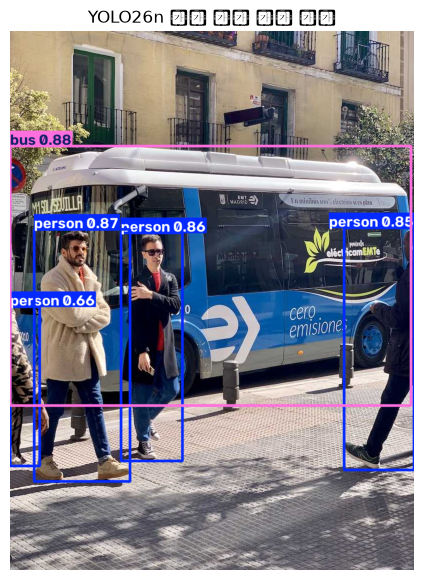

저장 위치: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\outputs\base_yolo_prediction.png


In [10]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

if prediction is None:
    print("앞의 예측 셀을 성공시킨 뒤 다시 실행하세요.")
else:
    plotted_bgr = prediction.plot()
    plotted_rgb = cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 7))
    plt.imshow(plotted_rgb)
    plt.title("YOLO26n 기본 모델 탐지 결과")
    plt.axis("off")
    plt.show()

    result_path = PROJECT_ROOT / "outputs" / "base_yolo_prediction.png"
    cv2.imwrite(str(result_path), plotted_bgr)
    print("저장 위치:", result_path)

### Bounding Box / Confidence 직접 살펴보기

- **클래스(Class)**: 모델이 인식한 객체 종류
- **박스(Bounding Box)**: `[x1, y1, x2, y2]` (픽셀 좌표)
- **Confidence**: 예측 신뢰도. **사람의 발견 난이도나 은신 점수와 같은 값이 아니다.**

In [11]:
if prediction is None:
    print("예측 결과가 없습니다.")
else:
    for i, box in enumerate(prediction.boxes, start=1):
        class_id = int(box.cls.item())
        print({
            "순번": i,
            "class_id": class_id,
            "class_name": prediction.names[class_id],
            "confidence": round(float(box.conf.item()), 4),
            "bbox_xyxy": [round(v, 1) for v in box.xyxy[0].tolist()],
        })
    if len(prediction.boxes) == 0:
        print("탐지 결과가 없습니다. 기본 모델이라 게임 캐릭터 탐지가 안 될 수 있습니다.")

{'순번': 1, 'class_id': 5, 'class_name': 'bus', 'confidence': 0.8805, 'bbox_xyxy': [0.0, 230.5, 803.2, 750.7]}
{'순번': 2, 'class_id': 0, 'class_name': 'person', 'confidence': 0.872, 'bbox_xyxy': [48.6, 397.7, 240.3, 902.4]}
{'순번': 3, 'class_id': 0, 'class_name': 'person', 'confidence': 0.8607, 'bbox_xyxy': [222.9, 404.8, 345.5, 861.0]}
{'순번': 4, 'class_id': 0, 'class_name': 'person', 'confidence': 0.8465, 'bbox_xyxy': [669.6, 394.5, 809.9, 879.4]}
{'순번': 5, 'class_id': 0, 'class_name': 'person', 'confidence': 0.6562, 'bbox_xyxy': [0.2, 552.9, 59.7, 871.3]}


## ⑦ 팀원과 연결할 YOLO Tool 함수의 기본 형태

`detect_objects()`는 **현재 모델이 탐지한 객체의 위치와 신뢰도를 반환**한다. 지금은 기본 COCO 클래스가 나오며, 추후 `best.pt`로 모델 경로를 변경하면 메챠 캐릭터 전용 탐지 Tool이 된다.

이 함수는 **스크린샷 → 탐지 결과 리스트** 구조로 설계했으므로 UI 담당자와 점수 담당자가 사용하기 쉽다.

In [12]:
from ultralytics import YOLO


def detect_objects(image_path, weights="yolo26n.pt", confidence=0.25):
    model = YOLO(str(weights))
    result = model.predict(source=str(image_path), conf=confidence, verbose=False)[0]
    objects = []
    for box in result.boxes:
        class_id = int(box.cls.item())
        objects.append({
            "class_id": class_id,
            "class_name": result.names[class_id],
            "bbox": [round(x, 1) for x in box.xyxy[0].tolist()],
            "confidence": round(float(box.conf.item()), 4),
        })
    return objects

print("✅ detect_objects 함수 준비 완료")
print("사용 예: detect_objects('samples/test.png', weights='yolo26n.pt')")
print("추후 학습 후: weights='runs/detect/camo_v1/weights/best.pt'")

✅ detect_objects 함수 준비 완료
사용 예: detect_objects('samples/test.png', weights='yolo26n.pt')
추후 학습 후: weights='runs/detect/camo_v1/weights/best.pt'


## ⑧ 메챠 캐릭터 학습을 위한 데이터셋 설정 준비

오늘은 4~5장 **라벨링 형식 시연**을 준비하는 단계이므로, 이 셀은 학습할 준비만 한다.

YOLO Detection의 학습 데이터는 다음처럼 구성한다.

```text
dataset/
├── images/
│   ├── train/
│   ├── val/
│   └── test/
├── labels/
│   ├── train/
│   ├── val/
│   └── test/
└── data.yaml
```

`data.yaml`의 클래스는 **하나만** 사용한다: `0: chameleon`.

아래 코드는 `data.yaml`이 **없을 때만 새로 만든다.**

In [13]:
from pathlib import Path
import yaml

DATA_YAML = PROJECT_ROOT / "dataset" / "data.yaml"
config = {
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "chameleon"},
}

if not DATA_YAML.exists():
    DATA_YAML.write_text(
        yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
        encoding="utf-8",
    )
    print("✅ 새 data.yaml 생성:", DATA_YAML)
else:
    print("ℹ️ 기존 data.yaml 보존:", DATA_YAML)
print(DATA_YAML.read_text(encoding="utf-8"))

ℹ️ 기존 data.yaml 보존: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\dataset\data.yaml
path: C:/Users/user/Downloads/camo-score-20261125T050906Z-1-001/camo-score/dataset
train: images/train
val: images/val
names:
  0: chameleon



In [87]:

from pathlib import Path
import sys

# 현재 노트북의 Python 환경 확인
print("Python 경로:", sys.executable)

# 기존 노트북에서 생성한 PROJECT_ROOT 사용
DATASET_ROOT = PROJECT_ROOT / "dataset"

# Roboflow 데이터셋 경로
TRAIN_IMAGES = DATASET_ROOT / "train" / "images"
TRAIN_LABELS = DATASET_ROOT / "train" / "labels"

# 기존 노트북의 폴더 구조도 지원
if not TRAIN_IMAGES.exists():
    TRAIN_IMAGES = DATASET_ROOT / "images" / "train"
    TRAIN_LABELS = DATASET_ROOT / "labels" / "train"

assert TRAIN_IMAGES.exists(), "이미지 폴더를 찾지 못했습니다."
assert TRAIN_LABELS.exists(), "라벨 폴더를 찾지 못했습니다."

image_extensions = {".png", ".jpg", ".jpeg"}

image_files = sorted(
    p for p in TRAIN_IMAGES.iterdir()
    if p.suffix.lower() in image_extensions
)

print("이미지 개수:", len(image_files))

for image_path in image_files:
    label_path = TRAIN_LABELS / f"{image_path.stem}.txt"

    assert label_path.exists(), (
        f"라벨 파일 없음: {image_path.name}"
    )

    print(f"✅ {image_path.name} → {label_path.name}")

assert len(image_files) >= 2, "이미지가 최소 2장 필요합니다."


Python 경로: c:\Users\user\anaconda3\envs\meccha-yolo\python.exe
이미지 개수: 100
✅ -2026-11-25-154826_png.rf.bcc76736fcb86b389ade97acca1fda68.jpg → -2026-11-25-154826_png.rf.bcc76736fcb86b389ade97acca1fda68.txt
✅ -2026-11-25-154846_png.rf.9f5e50c0fbf2de3bd813d75be1ff65ae.jpg → -2026-11-25-154846_png.rf.9f5e50c0fbf2de3bd813d75be1ff65ae.txt
✅ -2026-11-25-154859_png.rf.8e997d3dcc674750a8276be8ca378372.jpg → -2026-11-25-154859_png.rf.8e997d3dcc674750a8276be8ca378372.txt
✅ -2026-11-25-155327_png.rf.fd50bbf1d26102e3fa838eeaa5a655c4.jpg → -2026-11-25-155327_png.rf.fd50bbf1d26102e3fa838eeaa5a655c4.txt
✅ -2026-11-25-160159_png.rf.73a44ef193c04384f922789868f6d6cb.jpg → -2026-11-25-160159_png.rf.73a44ef193c04384f922789868f6d6cb.txt
✅ 4_png.rf.9eb01f677f9f486a13b88268687661e7.jpg → 4_png.rf.9eb01f677f9f486a13b88268687661e7.txt
✅ 7_png.rf.fb4116106db06f7534f20c8f3b24dea1.jpg → 7_png.rf.fb4116106db06f7534f20c8f3b24dea1.txt
✅ 9_png.rf.b3fbbdd2eb0b98ab44fe8324231a3e9d.jpg → 9_png.rf.b3fbbdd2eb0b98ab44fe8324

In [88]:

from pathlib import Path

DATASET_ROOT = PROJECT_ROOT / "dataset"
extensions = {".png", ".jpg", ".jpeg"}

folders = [
    "train/images",
    "valid/images",
    "val/images",
    "test/images",
    "images/train",
    "images/val"
]

for folder in folders:
    path = DATASET_ROOT / folder

    if path.exists():
        count = sum(
            1 for p in path.iterdir()
            if p.suffix.lower() in extensions
        )
        print(f"{folder}: {count}장")


images/train: 100장
images/val: 28장


In [89]:

from pathlib import Path

DATASET_ROOT = PROJECT_ROOT / "dataset"

for split in ["train", "val"]:
    image_dir = DATASET_ROOT / "images" / split
    label_dir = DATASET_ROOT / "labels" / split

    assert label_dir.exists(), f"라벨 폴더 없음: {label_dir}"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    labels = list(label_dir.glob("*.txt"))

    print(f"{split.upper()}")
    print("이미지:", len(images))
    print("TXT:", len(labels))

    for image in images:
        label = label_dir / f"{image.stem}.txt"
        assert label.exists(), f"라벨 누락: {image.name}"


TRAIN
이미지: 100
TXT: 100
VAL
이미지: 28
TXT: 28


In [90]:

import yaml

DATASET_ROOT = PROJECT_ROOT / "dataset"

config = {
    "path": DATASET_ROOT.resolve().as_posix(),
    "train": "images/train",
    "val": "images/val",
    "names": {0: "chameleon"}
}

TRAIN_YAML = DATASET_ROOT / "data.yaml"

with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("YAML 준비 완료!")
print(TRAIN_YAML)
print(config)


YAML 준비 완료!
C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\dataset\data.yaml
{'path': 'C:/Users/user/Downloads/camo-score-20261125T050906Z-1-001/camo-score/dataset', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'chameleon'}}


In [91]:

import sys
import torch

print("Python 경로:", sys.executable)
print("PyTorch 버전:", torch.__version__)
print("PyTorch CUDA 빌드:", torch.version.cuda)
print("CUDA 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))


Python 경로: c:\Users\user\anaconda3\envs\meccha-yolo\python.exe
PyTorch 버전: 2.14.1+cu126
PyTorch CUDA 빌드: 12.6
CUDA 사용 가능: True
GPU 이름: NVIDIA GeForce RTX 3060


In [92]:

from pathlib import Path

print("프로젝트 경로:", PROJECT_ROOT)

for folder in ["dataset", "dataset_corrected"]:
    path = PROJECT_ROOT / folder

    print(f"\n===== {folder} =====")
    print("폴더 존재:", path.exists())
    print("YAML 존재:", (path / "data.yaml").exists())
    print("Train 존재:", (path / "images" / "train").exists())
    print("Val 존재:", (path / "images" / "val").exists())


프로젝트 경로: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score

===== dataset =====
폴더 존재: True
YAML 존재: True
Train 존재: True
Val 존재: True

===== dataset_corrected =====
폴더 존재: False
YAML 존재: False
Train 존재: False
Val 존재: False


In [93]:

from pathlib import Path
import shutil
from collections import Counter

DATASET_ROOT = PROJECT_ROOT / "dataset"
LABEL_ROOT = DATASET_ROOT / "labels"
BACKUP_ROOT = PROJECT_ROOT / "labels_backup"

# 원본 라벨 백업 (최초 실행 시에만)
if not BACKUP_ROOT.exists():
    shutil.copytree(LABEL_ROOT, BACKUP_ROOT)
    print("원본 라벨 백업 완료")

# Train과 Validation 모두 수정
for split in ["train", "val"]:

    label_dir = LABEL_ROOT / split
    modified_files = 0
    modified_objects = 0

    for txt in sorted(label_dir.glob("*.txt")):

        lines = txt.read_text(
            encoding="utf-8-sig"
        ).splitlines()

        new_lines = []
        changed = False

        for line in lines:

            if not line.strip():
                continue

            parts = line.split()

            assert len(parts) == 5, (
                f"잘못된 라벨 형식: {txt.name}"
            )

            # 클래스 1을 0으로 수정
            if parts[0] == "1":
                parts[0] = "0"
                changed = True
                modified_objects += 1

            new_lines.append(" ".join(parts))

        if changed:
            txt.write_text(
                "\n".join(new_lines) + "\n",
                encoding="utf-8"
            )
            modified_files += 1

    print(f"\n===== {split.upper()} =====")
    print("수정된 파일:", modified_files)
    print("수정된 객체:", modified_objects)

print("\n클래스 번호 수정 완료!")



===== TRAIN =====
수정된 파일: 0
수정된 객체: 0

===== VAL =====
수정된 파일: 0
수정된 객체: 0

클래스 번호 수정 완료!


In [94]:

from collections import Counter

for split in ["train", "val"]:

    class_counts = Counter()
    empty_count = 0

    label_dir = DATASET_ROOT / "labels" / split

    for txt in label_dir.glob("*.txt"):

        lines = [
            line for line in
            txt.read_text(encoding="utf-8-sig").splitlines()
            if line.strip()
        ]

        if not lines:
            empty_count += 1
            continue

        for line in lines:
            class_counts[int(line.split()[0])] += 1

    print(f"\n===== {split.upper()} =====")
    print("클래스별 객체 수:", dict(class_counts))
    print("빈 라벨 파일:", empty_count)

    assert set(class_counts) == {0}, "클래스 오류 발생"

print("\n모든 클래스 검사 통과!")



===== TRAIN =====
클래스별 객체 수: {0: 88}
빈 라벨 파일: 12

===== VAL =====
클래스별 객체 수: {0: 29}
빈 라벨 파일: 0

모든 클래스 검사 통과!


In [95]:

import yaml

TRAIN_YAML = DATASET_ROOT / "data.yaml"

config = {
    "path": DATASET_ROOT.resolve().as_posix(),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {0: "chameleon"}
}

with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# 이전 학습의 캐시 제거
for cache in DATASET_ROOT.rglob("*.cache"):
    if cache.is_file():
        cache.unlink()
        print("캐시 제거:", cache.name)

print("YAML 설정 완료:", TRAIN_YAML)
print("파일 존재:", TRAIN_YAML.exists())


캐시 제거: train.cache
캐시 제거: val.cache
YAML 설정 완료: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\dataset\data.yaml
파일 존재: True


In [96]:

from ultralytics import YOLO
from pathlib import Path
import torch

# GPU 확인
assert torch.cuda.is_available(), "GPU 인식 실패"

print("학습 장치:", torch.cuda.get_device_name(0))

# 기존 dataset 폴더 사용
DATASET_ROOT = PROJECT_ROOT / "dataset"
TRAIN_YAML = DATASET_ROOT / "data.yaml"

assert TRAIN_YAML.exists(), "YAML 파일 없음"

print("사용할 데이터셋:", TRAIN_YAML)

# 사전학습 모델 불러오기
train_model = YOLO("yolo26n.pt")

# 모델 학습
train_model.train(
    data=str(TRAIN_YAML),
    epochs=100,
    patience=25,
    imgsz=640,
    batch=4,
    rect=True,
    workers=0,
    device=0,
    seed=42,
    plots=True,
    project=str(PROJECT_ROOT / "runs" / "detect"),
    name="meccha_class_fixed_n640"
)

# 학습된 모델 저장 위치
BEST_PT = (
    Path(train_model.trainer.save_dir)
    / "weights"
    / "best.pt"
)

print("학습 완료:", BEST_PT.exists())
print("저장 경로:", BEST_PT)


학습 장치: NVIDIA GeForce RTX 3060
사용할 데이터셋: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\dataset\data.yaml
Ultralytics 8.4.218  Python-3.11.18 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=Non

검증 이미지 개수: 28
테스트 이미지: frame_007_png.rf.07f984b03de48e267dc5df9c89686fa5.jpg
탐지된 객체 수: 1
좌표: [200.8730926513672, 199.07510375976562, 285.7727966308594, 275.35894775390625]
신뢰도: 0.8205770254135132


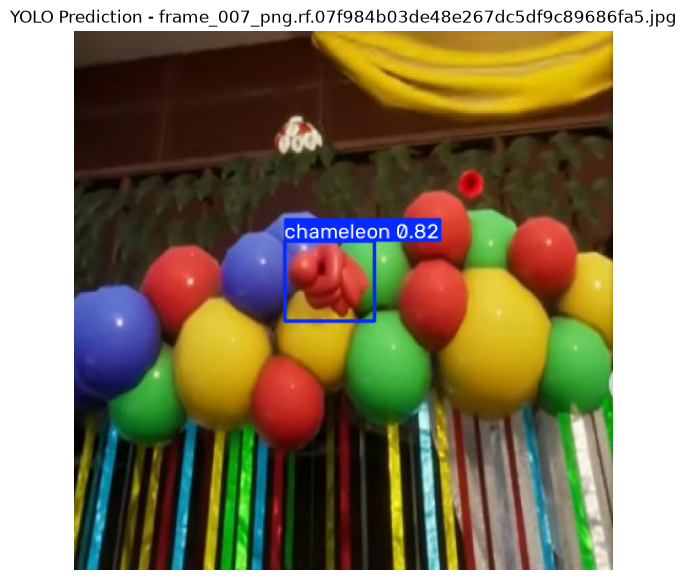

In [107]:

from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import random

# 1. 학습된 YOLO 모델 불러오기
meccha_model = YOLO(str(BEST_PT))

# 2. 검증 이미지 폴더 경로
VAL_DIR = PROJECT_ROOT / "dataset" / "images" / "val"

# 3. 검증 이미지 목록 만들기
val_images = sorted([
    p for p in VAL_DIR.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
])

print("검증 이미지 개수:", len(val_images))

assert len(val_images) > 0, "검증 이미지가 없습니다."

# 4. 검증 이미지 랜덤 선택
test_image = random.choice(val_images)

print("테스트 이미지:", test_image.name)

# 5. YOLO 모델로 탐지
result = meccha_model.predict(
    source=str(test_image),
    conf=0.1,
    verbose=False
)[0]

# 6. 탐지 결과 출력
print("탐지된 객체 수:", len(result.boxes))

for box in result.boxes:
    print("좌표:", box.xyxy[0].tolist())
    print("신뢰도:", float(box.conf[0]))

# 7. 탐지 결과 이미지 출력
annotated = result.plot()
annotated = cv2.cvtColor(
    annotated, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated)
plt.title(f"YOLO Prediction - {test_image.name}")
plt.axis("off")
plt.show()


In [21]:

from pathlib import Path
from ultralytics import YOLO

print("현재 모델 파일:", BEST_PT)
print("파일 존재:", Path(BEST_PT).exists())

meccha_model = YOLO(str(BEST_PT))

print("탐지 클래스:", meccha_model.names)
print("모델 작업 유형:", meccha_model.task)


현재 모델 파일: C:\Users\user\Downloads\camo-score-20261125T050906Z-1-001\camo-score\runs\detect\meccha_gpu_v1-3\weights\best.pt
파일 존재: True
탐지 클래스: {0: 'chameleon'}
모델 작업 유형: detect


## ⑨ CVAT 라벨을 내보낸 뒤 검수하는 코드 (라벨링 이후 실행)

**라벨 규칙:** 메챠 캐릭터는 잘 숨었든 못 숨었든 모두 `chameleon` 하나의 클래스로 표시한다. CVAT에서 `Ultralytics YOLO Detection`으로 내보낸 **이미지**와 대응하는 **`.txt` 파일**을 아래 경로에 넣는다.

- `samples/pilot/images/scene_001.png`
- `samples/pilot/labels/scene_001.txt`

YOLO Detection 라벨 한 줄: `class_id x_center y_center width height` (0~1 정규화). 아래 셀은 이미지/라벨의 이름 대응, 값 개수, 좌표 범위를 확인한다. 정확한 박스 위치는 다음 시각화 단계에서 눈으로 검토해야 한다.

In [22]:
from pathlib import Path

PILOT_IMAGES = PROJECT_ROOT / "samples" / "pilot" / "images"
PILOT_LABELS = PROJECT_ROOT / "samples" / "pilot" / "labels"

pilot_images = sorted(p for p in PILOT_IMAGES.iterdir()
                      if p.suffix.lower() in {".png", ".jpg", ".jpeg"})
print("Pilot 이미지 수:", len(pilot_images))

if not pilot_images:
    print("아직 라벨링한 이미지를 넣지 않았습니다. CVAT 내보내기 후 다시 실행하세요.")

for image_path in pilot_images:
    label_path = PILOT_LABELS / f"{image_path.stem}.txt"
    if not label_path.exists():
        print("❌ 대응 라벨 없음:", image_path.name)
        continue
    lines = [line.strip() for line in label_path.read_text(encoding="utf-8").splitlines()
             if line.strip()]
    issues = []
    for line_no, line in enumerate(lines, 1):
        try:
            values = line.split()
            if len(values) != 5:
                raise ValueError("숫자 5개 필요")
            cls = int(values[0])
            cx, cy, w, h = map(float, values[1:])
            if cls != 0 or w <= 0 or h <= 0:
                raise ValueError("클래스 또는 크기 오류")
            if not all(0 <= v <= 1 for v in (cx, cy, w, h)):
                raise ValueError("정규화 좌표 범위 오류")
            if not (0 <= cx-w/2 <= cx+w/2 <= 1 and
                    0 <= cy-h/2 <= cy+h/2 <= 1):
                raise ValueError("박스가 이미지 경계 밖에 있음")
        except Exception as exc:
            issues.append(f"{line_no}행: {exc}")
    print(("✅" if not issues else "❌"), image_path.name,
          "박스 수:", len(lines), "문제:", issues or "없음")

Pilot 이미지 수: 0
아직 라벨링한 이미지를 넣지 않았습니다. CVAT 내보내기 후 다시 실행하세요.


### PILOT 정답 박스 직접 시각화하기

여기서 보이는 **녹색 사각형은 YOLO가 예측한 게 아니라 CVAT에서 직접 그린 정답 박스**다. 캐릭터를 정확하게 감싸는지 확인한다.

In [23]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def visualize_annotation(image_path):
    image_path = Path(image_path)
    label_path = PILOT_LABELS / f"{image_path.stem}.txt"
    if not label_path.exists():
        print("라벨 파일 없음:", label_path)
        return
    image = Image.open(image_path).convert("RGB")
    iw, ih = image.size
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(image)
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        cls, cx, cy, w, h = map(float, line.split())
        x1, y1 = (cx-w/2)*iw, (cy-h/2)*ih
        ax.add_patch(Rectangle((x1, y1), w*iw, h*ih,
                               fill=False, linewidth=2, edgecolor="lime"))
        ax.text(x1, max(y1-6, 0), "chameleon", color="lime", fontsize=11)
    ax.set_title(image_path.name + " — 사람이 만든 정답 라벨")
    ax.axis("off")
    plt.show()

for sample in pilot_images[:5]:
    visualize_annotation(sample)

## ⑩ 전용 모델 추가 학습 코드 — 준비만 해 두기

여기서부터가 앞으로 만들 **진짜 메챠 전용 YOLO**다. 학습 데이터가 충분히 모이면 `YOLO("yolo26n.pt")`에서 출발하여 `model.train(data=...)`로 `chameleon` 1개 클래스를 추가 학습한다.

⚠️ **4~5장은 학습 성능 평가에 매우 부족하다.** 아래 셀은 기본적으로 학습하지 않도록 잠가 두었다. 학습·검증 이미지와 라벨을 준비한 뒤에만 `RUN_TRAINING=True`로 변경한다.

In [24]:
from pathlib import Path
from ultralytics import YOLO

RUN_TRAINING = False  # 학습 데이터 충분히 확보한 뒤 True로 변경

train_dir = PROJECT_ROOT / "dataset" / "images" / "train"
val_dir = PROJECT_ROOT / "dataset" / "images" / "val"
img_exts = {".jpg", ".jpeg", ".png"}
train_images = [p for p in train_dir.iterdir() if p.suffix.lower() in img_exts]
val_images = [p for p in val_dir.iterdir() if p.suffix.lower() in img_exts]

print(f"Train: {len(train_images)}장, Val: {len(val_images)}장")
if RUN_TRAINING:
    if not train_images or not val_images:
        raise RuntimeError("train/val 이미지와 라벨을 먼저 준비하세요.")
    custom_model = YOLO("yolo26n.pt")
    custom_model.train(
        data=str(DATA_YAML),
        epochs=30,
        imgsz=640,
        batch=4,
        project=str(PROJECT_ROOT / "runs" / "detect"),
        name="meccha_v1",
    )
    print("학습 완료! runs/detect/meccha_v1/weights/best.pt 파일 확인")
else:
    print("⏭️ 학습은 아직 실행하지 않았습니다. 오늘은 환경/기본 모델/라벨 검수가 목표입니다.")

Train: 82장, Val: 6장
⏭️ 학습은 아직 실행하지 않았습니다. 오늘은 환경/기본 모델/라벨 검수가 목표입니다.


## ⑪ 오늘 작업 결과 기록 / Git 저장 팁

**이 노트북에서 확인할 완료 항목**

- [ ] `Python (meccha-yolo)` 커널을 선택했고, `sys.executable`로 환경을 확인했다.
- [ ] 필요한 라이브러리들이 정상 import 된다.
- [ ] `YOLO("yolo26n.pt")`로 기본 모델이 로드된다.
- [ ] 게임 스크린샷 또는 버스 예제에서 예측 이미지가 노트북에 나타난다.
- [ ] `chameleon` 1클래스 `data.yaml`을 준비했다.
- [ ] (선택) CVAT에서 4~5개 이미지에 정답 박스를 만들고 라벨을 시각화했다.

**Git (Sourcetree):** 작업 브랜치 `yolo/train`에서 이 `.ipynb`와 `dataset/data.yaml`을 커밋한다. `runs/`, `outputs/`, `*.pt`, 가상환경은 `.gitignore`로 제외한다. 4~5장 파일은 용량과 팀의 공유 정책을 확인한 뒤 추가한다.

**주의:** 현재 코드는 *기본 모델 준비 + 전용 모델 학습을 위한 틀*이다. 메챠 캐릭터를 안정적으로 찾는 전용 모델이 완성되었다고 주장하면 안 된다.

공식 참고: [YOLO Detection](https://docs.ultralytics.com/tasks/detect/) · [학습 모드](https://docs.ultralytics.com/modes/train/) · [커널 설치](https://ipython.readthedocs.io/en/stable/install/kernel_install.html).